# Balls

#TODO:

      1- Find out if front, angle or top image. For front and angle needs to remove shadows/holes near top and right border

      2- Blue ball gets eaten a bit from the mask, most cases still detects

      3- Get color values from histogram distribution inside circle/bouding box

In [94]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import itertools
import numpy as np
import math

In [131]:
DATA_DIR = Path("./../data")
IMAGE_PATH = DATA_DIR / "development_set/4a_png.rf.a6bb5c5706fd8628eb53d34a122cf441.jpg"


#IMAGE_PATH = DATA_DIR / "development_set/3f_png.rf.81c7e132365ef95bb19380ca389025f6.jpg"

IMAGE_PATH = DATA_DIR / "development_set/3f_png.rf.81c7e132365ef95bb19380ca389025f6.jpg"



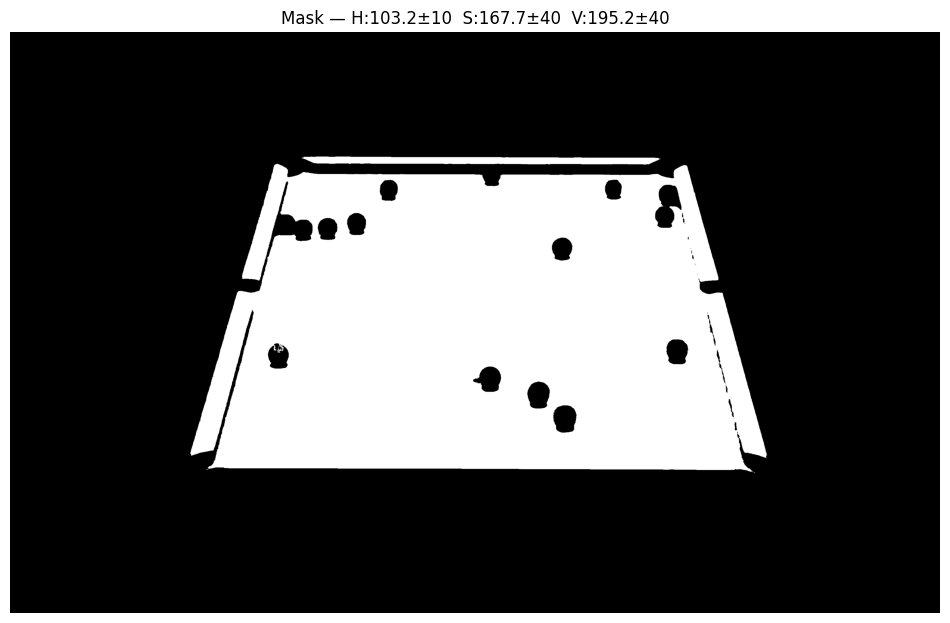

In [132]:
h_med = 103.2
s_med = 167.7   
v_med = 195.2

# Define tolerance around the median values
h_tol = 10
s_tol = 40
v_tol = 40

lower_blue = np.array([h_med - h_tol, s_med - s_tol, v_med - v_tol])
upper_blue = np.array([h_med + h_tol, s_med + s_tol, v_med + v_tol])

# Clip to valid HSV ranges
lower_blue = np.clip(lower_blue, [0, 0, 0], [179, 255, 255])
upper_blue = np.clip(upper_blue, [0, 0, 0], [179, 255, 255])

image = cv2.imread(str(IMAGE_PATH))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

hsv_image = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
mask_table = cv2.inRange(hsv_image, lower_blue, upper_blue)

plt.figure(figsize=(12, 8))
plt.imshow(mask_table, cmap='gray')
plt.axis('off')
plt.title(f'Mask — H:{h_med}±{h_tol}  S:{s_med}±{s_tol}  V:{v_med}±{v_tol}')
plt.show()

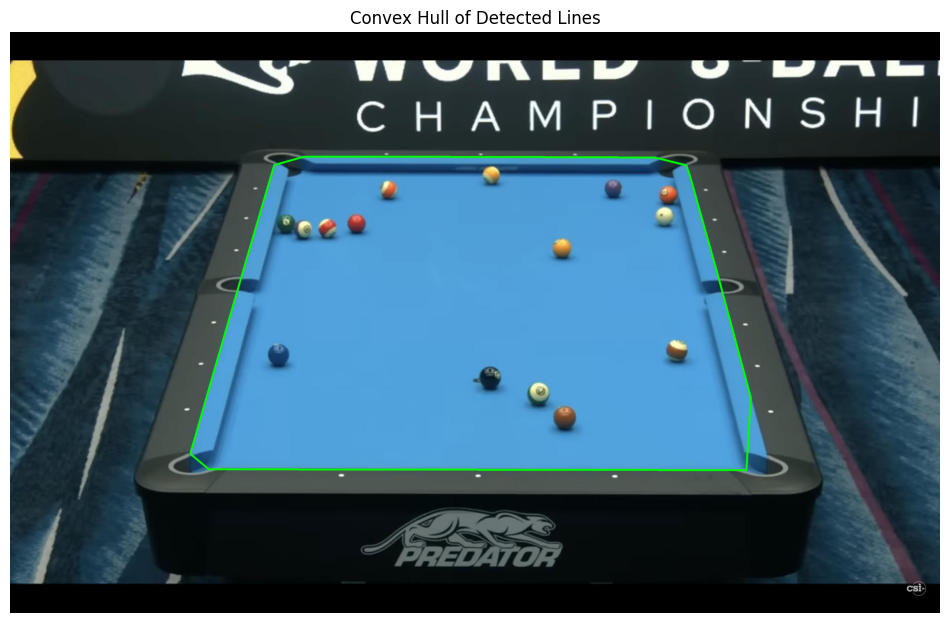

In [133]:
edges = cv2.Canny(mask_table, 50, 150)

lines = cv2.HoughLinesP(
    edges,
    1,
    np.pi / 180,
    threshold=80,
    minLineLength=100,
    maxLineGap=80
)

tmp_lines = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    length = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)
    if length >= 250:
        tmp_lines.append(line)
lines = tmp_lines

pts = []
for line in lines:
    x1, y1, x2, y2 = line[0]
    pts.append((x1, y1))
    pts.append((x2, y2))

pts = np.array(pts)
hull = cv2.convexHull(pts)

line_image = image.copy()
cv2.polylines(line_image, [hull], isClosed=True, color=(0, 255, 0), thickness=5)

plt.figure(figsize=(12, 8))
plt.imshow(line_image)
plt.axis('off')
plt.title('Convex Hull of Detected Lines')
plt.show()

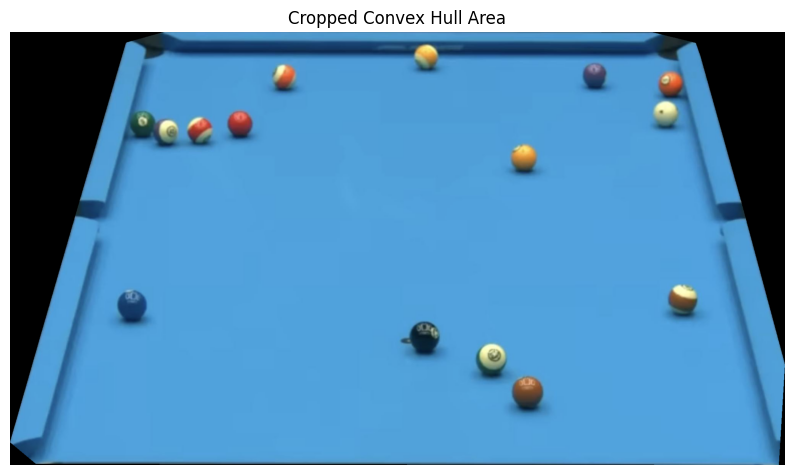

In [134]:
# 1. Create a black mask the same size as the image
mask = np.zeros(image.shape, dtype=np.uint8)

# 2. Fill the convex hull area with white
cv2.fillPoly(mask, [hull], (255, 255, 255))

# 3. Apply the mask to the original image
masked_image = cv2.bitwise_and(image, mask)

# 4. Crop to the bounding rectangle of the hull to remove black padding
x, y, w, h = cv2.boundingRect(hull)
final_crop = masked_image[y:y+h, x:x+w]

# Display result
plt.figure(figsize=(10, 6))
plt.imshow(final_crop)
plt.title('Cropped Convex Hull Area')
plt.axis('off')
plt.show()



In [135]:
hsv_crop = cv2.cvtColor(final_crop, cv2.COLOR_RGB2HSV)


-------------------------------

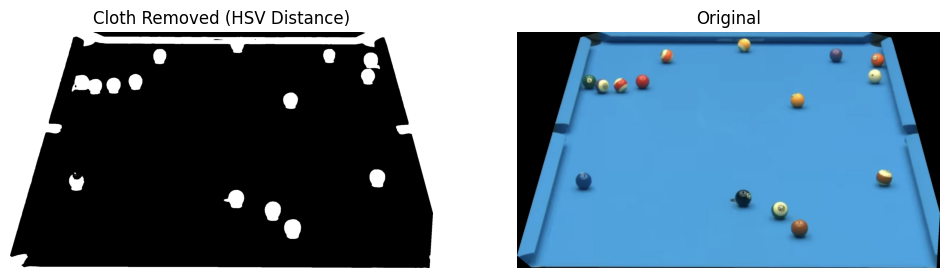

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Convert to HSV


# Estimate cloth color (median is robust)
h_med = 103.2
s_med = 167.7   
v_med = 195.2

cloth_color = np.array([h_med, s_med, v_med])

diff = np.linalg.norm(hsv_crop.astype(np.float32) - cloth_color, axis=2)


# --- Shadow detection ---
# Shadows values sampled
shadow_h = 106.1
shadow_s = 202.8
shadow_v = 97.4

h_channel = hsv_crop[:, :, 0].astype(np.float32)
s_channel = hsv_crop[:, :, 1].astype(np.float32)
v_channel = hsv_crop[:, :, 2].astype(np.float32)


# H: 103–105 | S: 155–183 | V: 100–130       
is_light_shadow = (
    (h_channel >= 103) & (h_channel <= 105) &
    (s_channel >= 155) & (s_channel <= 183) &
    (v_channel >= 100) & (v_channel <= 130)
)

# --- 2. Dark Shadow Filter ---
# H: 106 | S: 195–216 | V: 85–110

is_dark_shadow = (
    (h_channel >= 95) & (h_channel <= 115) &  # Widened Hue
    (s_channel > 184) &                       # Pushed right up to the ball's 183.5
    (v_channel < 114)                         # Pushed right up to the ball's 115.2
)

# --- 3. Combine and Apply Globally ---
is_shadow = is_light_shadow | is_dark_shadow

#Not using shadow mask on hole image, impossible to get the blue ball

mask = ((diff > 65)).astype(np.uint8) * 255


# Show
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(mask, cmap='gray')
plt.title('Cloth Removed (HSV Distance)')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(final_crop)
plt.title('Original')
plt.axis('off')
plt.show()

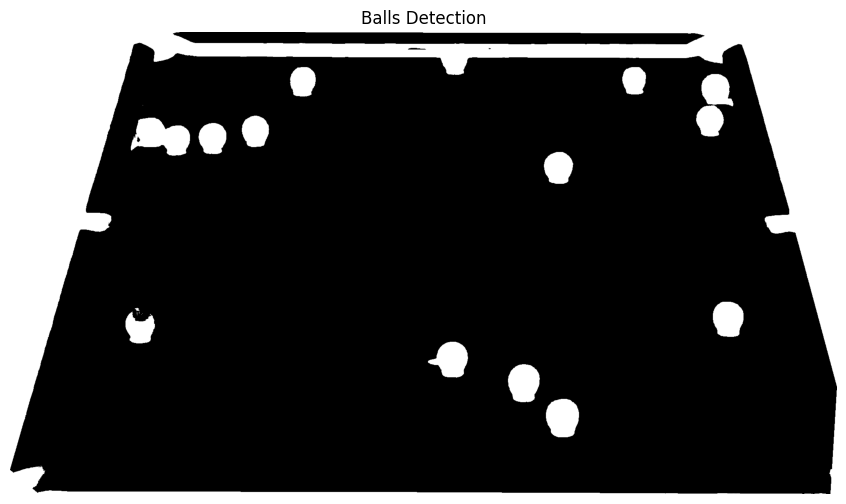

In [137]:

gray_mask = cv2.medianBlur(mask, 5)

#gray_mask = cv2.GaussianBlur(mask, (5, 5), 2)
plt.figure(figsize=(12, 6))
plt.imshow(mask, cmap='gray')
plt.title('Balls Detection')
plt.axis('off')
plt.show()

Found 14 circle(s)
  Ball at (1259,850) r=37
  Ball at (1353,940) r=42
  Ball at (600,239) r=33
  Ball at (1345,332) r=39
  Ball at (1758,699) r=39
  Ball at (718,116) r=31
  Ball at (495,257) r=34
  Ball at (1730,139) r=37
  Ball at (1530,116) r=30
  Ball at (1086,800) r=42
  Ball at (410,258) r=31
  Ball at (1716,218) r=38
  Ball at (326,718) r=44
  Ball at (344,250) r=41


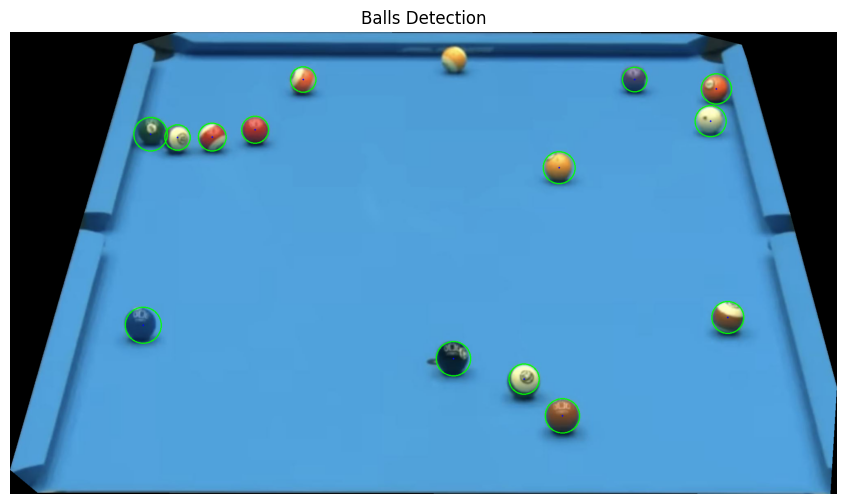

In [ ]:
# Do not fuck with the parameters, chaos ensues

circles = cv2.HoughCircles(
    gray_mask,          
    cv2.HOUGH_GRADIENT,
    dp=1.4,
    minDist=32,
    param1=40,
    param2=18,
    minRadius=21,
    maxRadius=48
)

result = final_crop.copy()

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    print(f"Found {len(circles)} circle(s)")
    for (cx, cy, r) in circles:
        if r < 12:
            print(f"  Skipped small blob at ({cx},{cy}) r={r}")
            continue
        cv2.circle(result, (cx, cy), r, (0, 255, 0), 2)
        cv2.circle(result, (cx, cy), 2, (0, 0, 255), -1)
        print(f"  Ball at ({cx},{cy}) r={r}")
else:
    print("No circles found")

plt.figure(figsize=(12, 6))
plt.imshow(result)
plt.title('Balls Detection')
plt.axis('off')
plt.show()

----------------- Down this line is shit I tried before and some experiments------------

Dominant HSV: H=100.5, S=158.7, V=212.3


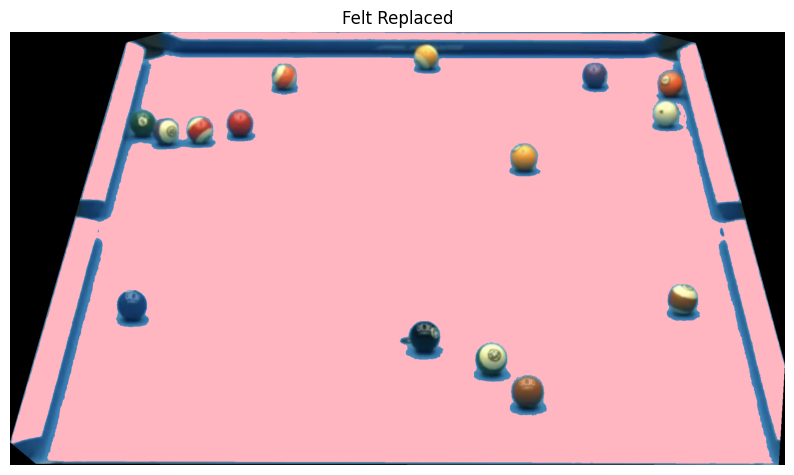

In [139]:
h, w = final_crop.shape[:2]
cy, cx = h // 2, w // 2
margin_y, margin_x = int(h * 0.4), int(w * 0.4)  # 20% each side = 40% total

center_region = final_crop[cy-margin_y:cy+margin_y, cx-margin_x:cx+margin_x]

# Get dominant color in HSV
center_hsv = cv2.cvtColor(center_region, cv2.COLOR_RGB2HSV)
mean_h = np.mean(center_hsv[:,:,0])
mean_s = np.mean(center_hsv[:,:,1])
mean_v = np.mean(center_hsv[:,:,2])
print(f"Dominant HSV: H={mean_h:.1f}, S={mean_s:.1f}, V={mean_v:.1f}")

# Build range around sampled values
# --- TWEAK THESE VALUES ---
h_low, h_high = 3, 5      # Strict Hue (The actual color)
s_low, s_high = 40, 40    # Saturation
v_low, v_high = 20, 50    # Brightness (Increase v_low to catch more shadows)

# Build the ranges using the specific variables
lower = np.array([mean_h - h_low,  mean_s - s_low,  mean_v - v_low]).clip(0, 255)
upper = np.array([mean_h + h_high, mean_s + s_high, mean_v + v_high]).clip(0, 255)


hsv_crop = cv2.cvtColor(final_crop, cv2.COLOR_RGB2HSV)
felt_mask_crop = cv2.inRange(hsv_crop, lower, upper)

# Apply pink
pink_crop = final_crop.copy()
pink_crop[felt_mask_crop == 255] = [255, 182, 193]

plt.figure(figsize=(10, 6))
plt.imshow(pink_crop)
plt.title('Felt Replaced')
plt.axis('off')
plt.show()

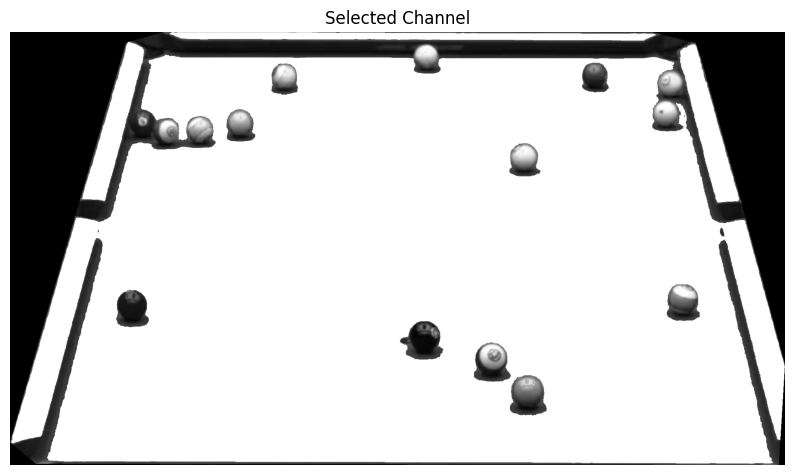

In [140]:

pink_crop_c1 =pink_crop[:, :, 0]
plt.figure(figsize=(10, 6))
plt.imshow(pink_crop_c1, cmap='gray')
plt.title('Selected Channel')
plt.axis('off')
plt.show()

Balls detected: 27


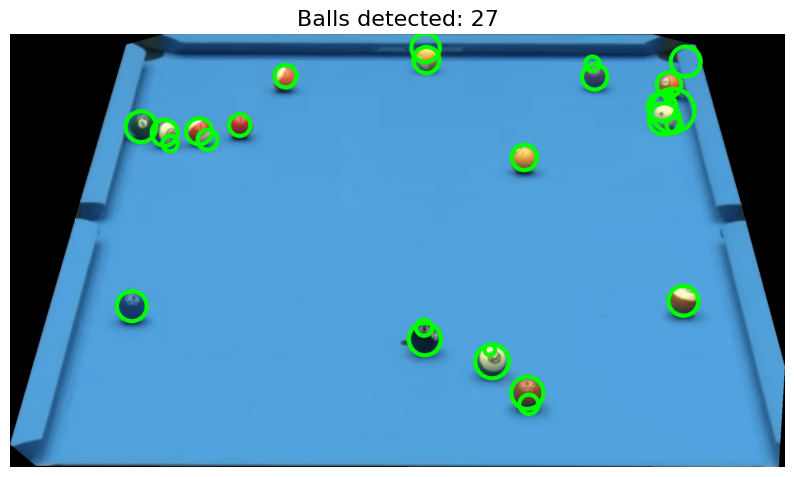

In [141]:
circles = cv2.HoughCircles(
    pink_crop_c1,        # input grayscale image
    cv2.HOUGH_GRADIENT, # detection method (only available option)
    dp=1,               # accumulator resolution matches image resolution
    minDist=30,         # minimum pixel distance between circle centers
    param1=60,          # canny edge upper threshold (lower = more edges)
    param2=20,          # accumulator threshold (lower = more circles detected)
    minRadius=9,       # minimum ball radius in pixels
    maxRadius=60        # maximum ball radius in pixels
)

vis=final_crop.copy()
#vis = cv2.cvtColor(result_interior, cv2.COLOR_GRAY2RGB)

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    for (x, y, r) in circles:
        cv2.circle(vis, (x, y), r, (0, 255, 0), 10)
    
    detection_count = len(circles)
    print(f"Balls detected: {detection_count}")
else:    
    detection_count = 0
    print("No balls detected.")

# 3. Display the result
plt.figure(figsize=(10, 6))
plt.title(f'Balls detected: {detection_count}', fontsize=16)
# Ensure we don't use cmap='gray' here so the green shows up
plt.imshow(vis,  cmap='grey') 
plt.axis('off')
plt.show()

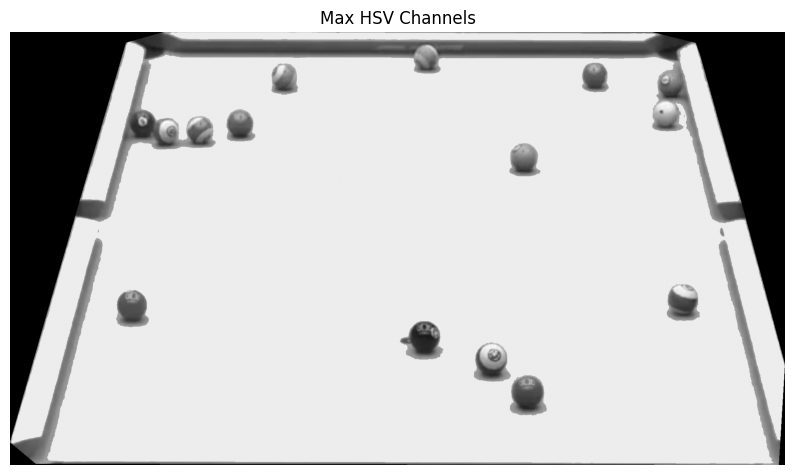

Balls detected: 26


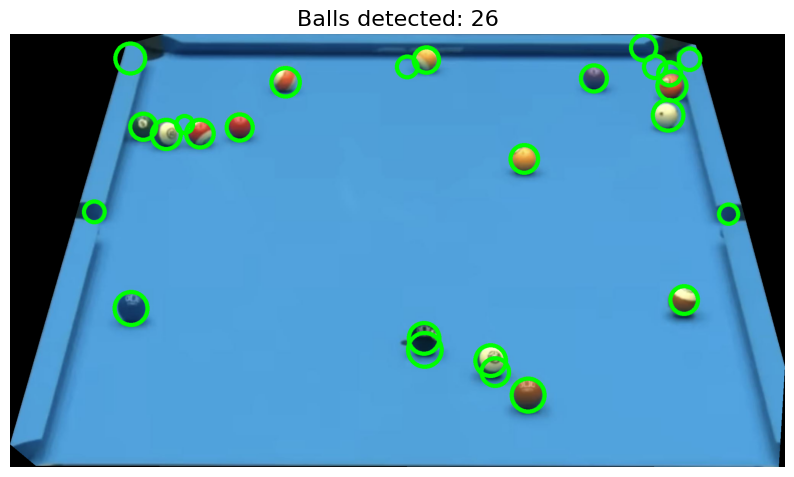

In [142]:
#combined = np.maximum(pink_crop[:,:,0], pink_crop[:,:,2]) #some balls on visible on hue, saturation, value channels take the max of each

combined=   (0.4*pink_crop[:,:,0] + 0.7 * pink_crop[:,:,2]).clip(0, 255).astype(np.uint8) #try to do weighted sums of the 3 channels

plt.figure(figsize=(10, 6))
plt.imshow(combined, cmap='gray')
plt.title('Max HSV Channels')
plt.axis('off')
plt.show()

circles = cv2.HoughCircles(
    combined,        # input grayscale image
    cv2.HOUGH_GRADIENT, # detection method (only available option)
    dp=1,               # accumulator resolution matches image resolution
    minDist=30,         # minimum pixel distance between circle centers
    param1=60,          # canny edge upper threshold (lower = more edges)
    param2=15,          # accumulator threshold (lower = more circles detected)
    minRadius=20,       # minimum ball radius in pixels
    maxRadius=45        # maximum ball radius in pixels
)

vis=final_crop.copy()
#vis = cv2.cvtColor(result_interior, cv2.COLOR_GRAY2RGB)

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    for (x, y, r) in circles:
        cv2.circle(vis, (x, y), r, (0, 255, 0), 10)
    
    detection_count = len(circles)
    print(f"Balls detected: {detection_count}")
else:    
    detection_count = 0
    print("No balls detected.")

# 3. Display the result
plt.figure(figsize=(10, 6))
plt.title(f'Balls detected: {detection_count}', fontsize=16)
# Ensure we don't use cmap='gray' here so the green shows up
plt.imshow(vis,  cmap='grey') 
plt.axis('off')
plt.show()

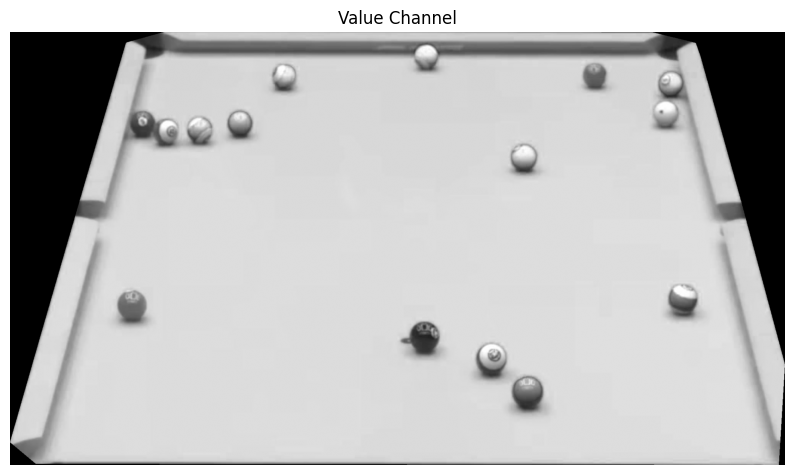

In [143]:
hsv_crop = cv2.cvtColor(final_crop, cv2.COLOR_RGB2HSV)
hsv_crop_c3 =hsv_crop[:, :, 2]
plt.figure(figsize=(10, 6))
plt.imshow(hsv_crop_c3, cmap='gray')
plt.title('Value Channel')
plt.axis('off')
plt.show()

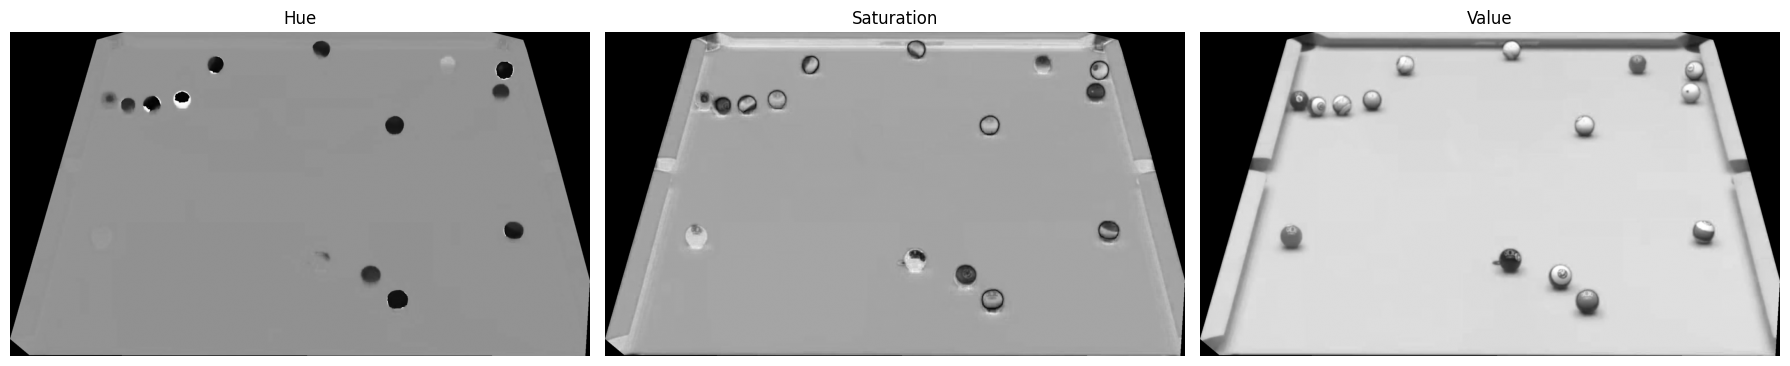

In [144]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (ax, title) in enumerate(zip(axes, ['Hue', 'Saturation', 'Value'])):
    ax.imshow(hsv_crop[:,:,i], cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

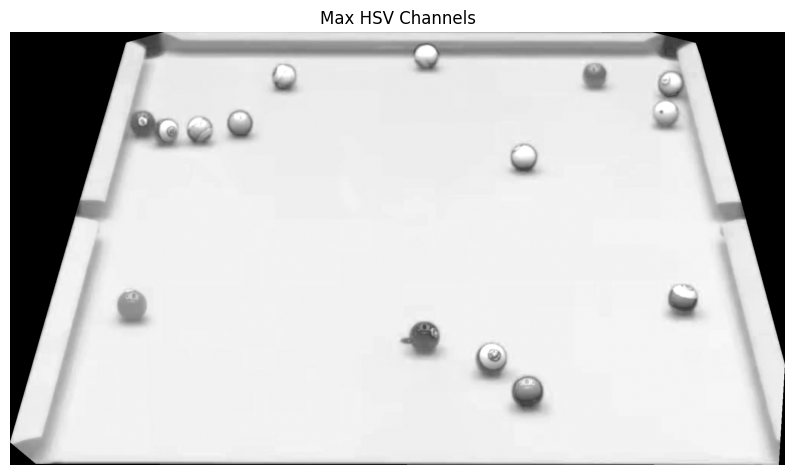

In [145]:
combined = np.maximum(hsv_crop[:,:,0], hsv_crop[:,:,1]) #some balls on visible on hue, saturation, value channels take the max of each
combined = np.maximum(combined, hsv_crop[:,:,2])

combined=   (0.3*combined + 0.8 * hsv_crop[:,:,2]).clip(0, 255).astype(np.uint8) #try to do weighted sums of the 3 channels

plt.figure(figsize=(10, 6))
plt.imshow(combined, cmap='gray')
plt.title('Max HSV Channels')
plt.axis('off')
plt.show()

Balls detected: 27


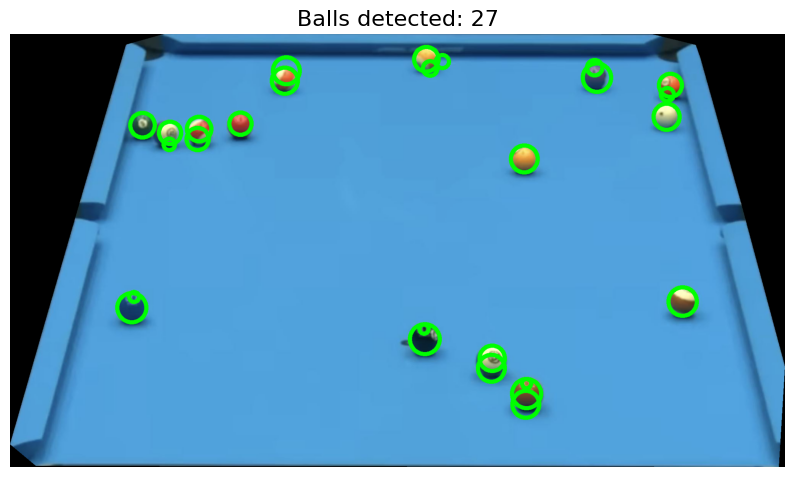

In [146]:
circles = cv2.HoughCircles(
    hsv_crop[:,:,2],        # input grayscale image
    cv2.HOUGH_GRADIENT, # detection method (only available option)
    dp=1,               # accumulator resolution matches image resolution
    minDist=25,         # minimum pixel distance between circle centers
    param1=60,          # canny edge upper threshold (lower = more edges)
    param2=19,          # accumulator threshold (lower = more circles detected)
    minRadius=10,       # minimum ball radius in pixels
    maxRadius=40        # maximum ball radius in pixels
)

vis=final_crop.copy()
#vis = cv2.cvtColor(result_interior, cv2.COLOR_GRAY2RGB)

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    for (x, y, r) in circles:
        cv2.circle(vis, (x, y), r, (0, 255, 0), 10)
    
    detection_count = len(circles)
    print(f"Balls detected: {detection_count}")
else:    
    detection_count = 0
    print("No balls detected.")

# 3. Display the result
plt.figure(figsize=(10, 6))
plt.title(f'Balls detected: {detection_count}', fontsize=16)
# Ensure we don't use cmap='gray' here so the green shows up
plt.imshow(vis,  cmap='grey') 
plt.axis('off')
plt.show()